In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base_file_path = "../data/interim/"
train_file_path = "../data/processed/"

In [2]:
df_concentration = pd.read_parquet(f"{base_file_path}concentration.parquet")
display(df_concentration)
df_wells = pd.read_parquet(f"{base_file_path}wells.parquet")
display(df_wells)

,well_id,t,concentration
0,Well_0416,2022-01-13,0.21
2,Well_0110,2025-02-02,0.31
4,Well_0150,2024-07-27,1.74
6,Well_0570,2025-10-18,21.42
7,Well_0149,2021-06-26,1.80
...,...,...,...
2838,Well_0467,2020-04-08,921.41
2840,Well_0637,2020-01-09,0.03
2842,Well_0118,2023-05-02,25.48
2843,Well_0681,2025-06-23,0.50


,well_id,x,y,z,permeability
3,Well_0213,1286.20,836.52,-26.54,9.606255
4,Well_0794,3918.96,1410.94,-115.29,4.490132
5,Well_0544,3984.60,3094.10,-131.42,4.369649
6,Well_0281,1034.06,1053.31,-13.70,16.449488
7,Well_0297,1269.88,988.13,-73.35,12.800393
...,...,...,...,...,...
850,Well_0072,1461.41,1502.93,-81.34,16.404673
851,Well_0107,1565.86,767.86,-116.05,5.211799
852,Well_0271,1432.38,1212.33,-43.33,13.288466
853,Well_0436,1022.23,849.38,-69.58,15.247819


В качестве базовой таблицы была выбрана concentration, т.к. она содержит фактически конечный ответ: номер скважины и кол-во концентрата. Первое слияние сделаем с таблицей с таблицей wells, содержащей фактические координаты каждой вышки.

In [3]:
df_train = df_concentration.merge(df_wells, how="left", on="well_id")
df_train

,well_id,t,concentration,x,y,z,permeability
0,Well_0416,2022-01-13,0.21,775.45,1083.71,-136.96,12.406732
1,Well_0110,2025-02-02,0.31,977.67,1448.81,-120.23,10.222438
2,Well_0150,2024-07-27,1.74,1089.10,1208.86,-108.82,16.016241
3,Well_0570,2025-10-18,21.42,4138.60,3994.44,-56.74,6.122623
4,Well_0149,2021-06-26,1.80,1156.58,930.72,-126.92,14.226079
...,...,...,...,...,...,...,...
2401,Well_0467,2020-04-08,921.41,1184.25,797.08,-21.77,11.064906
2402,Well_0637,2020-01-09,0.03,4475.79,3254.64,-38.36,4.512977
2403,Well_0118,2023-05-02,25.48,649.40,1217.73,-85.69,7.631058
2404,Well_0681,2025-06-23,0.50,4071.96,3771.17,-123.83,5.246263


Затем сделаем слияение с таблицей cores, дальнейший порядок не важен, берем случайную и сливаем со всем с чем сливается. В таблице cores описаны слои земной породы на разных глубинах, поэтому обычный merge не сработает, необходимо использовать merge_asof, который отсортирует данные, и подхватит в таблицу ближайшее нижнее значение.

In [4]:
df_cores = pd.read_parquet(f"{base_file_path}cores.parquet")

In [5]:
df_train.sort_values(by=["z"], inplace=True)

df_cores_sorted = df_cores.sort_values(by=["z_bottom"])

df_train = pd.merge_asof(
    df_train,
    df_cores_sorted[["well_id", "z_bottom", "lithology"]],
    left_on="z",
    right_on="z_bottom",
    by="well_id",
    direction="backward",
)

df_train["lithology"] = df_train["lithology"].fillna(value="unknown")
df_train.drop(columns=["z_bottom"], inplace=True)

In [6]:
df_train

,well_id,t,concentration,x,y,z,permeability,lithology
0,Well_0824,2025-05-17,0.06,4366.54,3606.99,-139.98,4.331969,unknown
1,Well_0824,2023-02-13,0.23,4366.54,3606.99,-139.98,4.331969,unknown
2,Well_0824,2023-09-13,0.02,4366.54,3606.99,-139.98,4.331969,unknown
3,Well_0824,2023-01-31,0.02,4366.54,3606.99,-139.98,4.331969,unknown
4,Well_0824,2020-04-21,0.16,4366.54,3606.99,-139.98,4.331969,unknown
...,...,...,...,...,...,...,...,...
2401,Well_0238,2020-11-30,336.78,1055.94,1294.81,-10.59,14.541197,clay
2402,Well_0524,2021-06-02,0.03,4856.91,3665.52,-10.28,4.493504,clay
2403,Well_0524,2024-01-29,0.00,4856.91,3665.52,-10.28,4.493504,clay
2404,Well_0524,2024-08-17,0.05,4856.91,3665.52,-10.28,4.493504,clay


Далее сольем с head

In [7]:
df_head = pd.read_parquet(f"{base_file_path}head.parquet")
df_head

,well_id,head,t
1,Well_0688,15.22,2022-09-21
2,Well_0446,35.76,2024-11-15
4,Well_0818,40.53,2025-03-17
5,Well_0237,37.71,2022-01-21
6,Well_0458,37.57,2021-03-05
...,...,...,...
1620,Well_0799,25.73,2021-01-14
1621,Well_0432,37.28,2021-11-12
1622,Well_0146,35.14,2022-02-02
1623,Well_0329,36.54,2023-01-28


In [8]:
df_head_sorted = df_head.sort_values(by=["t"])
df_head_sorted.rename(columns={"t": "head_t"}, inplace=True)
df_train = df_train.sort_values(by=["t"])

df_train = pd.merge_asof(
    df_train,
    df_head_sorted[["head_t", "well_id", "head"]],
    left_on="t",
    right_on="head_t",
    by="well_id",
    direction="backward",
)

In [9]:
df_train

,well_id,t,concentration,x,y,z,permeability,lithology,head_t,head
0,Well_0457,2020-01-01,1023.11,967.89,1102.82,-58.96,15.629940,sand,NaT,NaN
1,Well_0284,2020-01-03,1.72,628.66,1183.18,-114.51,7.700694,sand,NaT,NaN
2,Well_0785,2020-01-03,0.12,495.89,3827.56,-47.48,4.640666,sand,NaT,NaN
3,Well_0475,2020-01-05,1.80,1493.49,866.14,-104.15,6.526043,loam,NaT,NaN
4,Well_0421,2020-01-05,0.33,1618.22,1322.09,-124.90,11.359716,unknown,NaT,NaN
...,...,...,...,...,...,...,...,...,...,...
2401,Well_0674,2025-10-27,33.84,3974.96,2854.58,-72.94,4.338842,loam,2022-08-25,19.12
2402,Well_0277,2025-10-27,107.69,1059.72,781.86,-78.58,13.788869,sand,2022-10-10,36.89
2403,Well_0141,2025-10-29,79.27,1068.24,899.26,-80.30,15.244325,sand,2024-08-31,37.14
2404,Well_0267,2025-10-29,29.78,1489.72,989.50,-76.60,8.180902,sand,2024-03-14,34.42


Поручилось очень много NaN в хэд, пробуем заполнить средними значениями для скважины, для оставшихся заполним средними значениями всего датасета

In [10]:
mean_head_by_wells = df_head.groupby("well_id")["head"].mean()

df_train["head"] = df_train["head"].fillna(df_train["well_id"].map(mean_head_by_wells))

df_train["head"] = df_train["head"].fillna(df_train["head"].mean())

df_train.drop(columns=["head_t"], inplace=True)

In [11]:
df_train

,well_id,t,concentration,x,y,z,permeability,lithology,head
0,Well_0457,2020-01-01,1023.11,967.89,1102.82,-58.96,15.629940,sand,36.306667
1,Well_0284,2020-01-03,1.72,628.66,1183.18,-114.51,7.700694,sand,36.170000
2,Well_0785,2020-01-03,0.12,495.89,3827.56,-47.48,4.640666,sand,31.453333
3,Well_0475,2020-01-05,1.80,1493.49,866.14,-104.15,6.526043,loam,29.921734
4,Well_0421,2020-01-05,0.33,1618.22,1322.09,-124.90,11.359716,unknown,32.630000
...,...,...,...,...,...,...,...,...,...
2401,Well_0674,2025-10-27,33.84,3974.96,2854.58,-72.94,4.338842,loam,19.120000
2402,Well_0277,2025-10-27,107.69,1059.72,781.86,-78.58,13.788869,sand,36.890000
2403,Well_0141,2025-10-29,79.27,1068.24,899.26,-80.30,15.244325,sand,37.140000
2404,Well_0267,2025-10-29,29.78,1489.72,989.50,-76.60,8.180902,sand,34.420000


Далее будем сливать с датой последней откачки из df_pumping

In [12]:
df_pumping = pd.read_parquet(f"{base_file_path}pumping.parquet")

df_pumping

,well_id,pumping_rate,units,t
1,Well_0518,1162.81,m3/day,2024-07-01
2,Well_0005,327.50,m3/day,2025-12-01
4,Well_0010,356.73,m3/day,2022-10-01
5,Well_0515,1096.15,m3/day,2022-11-01
6,Well_0519,994.69,m3/day,2023-07-01
...,...,...,...,...
3234,Well_0013,295.11,m3/day,2025-09-01
3235,Well_0516,1368.65,m3/day,2021-04-01
3236,Well_0516,1434.06,m3/day,2024-03-01
3237,Well_0518,1139.50,m3/day,2025-11-01


In [13]:
df_pumping.sort_values(by=["t"], inplace=True)
df_pumping.rename(columns={"t":"pumping_t"}, inplace=True)

df_train.sort_values(by=["t"], inplace=True)

df_train = pd.merge_asof(
    df_train,
    df_pumping[["pumping_t", "well_id", "pumping_rate"]],
    left_on="t",
    right_on="pumping_t",
    by="well_id",
    direction="backward",
)

df_train["pumping_rate"] = df_train["pumping_rate"].fillna(0)
df_train.drop(columns=["pumping_t"], inplace=True)

In [14]:
df_abstraction = pd.read_parquet(f"{base_file_path}abstraction.parquet")
df_abstraction

,intake_name,x_center,y_center,t,total_abstraction_m3_day
0,Заречный водозабор,4000.0,3500.0,2020-01-01,26714.6
1,Заречный водозабор,4000.0,3500.0,2020-02-01,31722.3
2,Заречный водозабор,4000.0,3500.0,2020-03-01,38836.4
3,Заречный водозабор,4000.0,3500.0,2020-04-01,41624.0
4,Заречный водозабор,4000.0,3500.0,2020-05-01,42837.7
...,...,...,...,...,...
67,Заречный водозабор,4000.0,3500.0,2025-08-01,40293.2
68,Заречный водозабор,4000.0,3500.0,2025-09-01,35794.1
69,Заречный водозабор,4000.0,3500.0,2025-10-01,29547.1
70,Заречный водозабор,4000.0,3500.0,2025-11-01,28858.6


Далее сливаем с данными о сливе с конкретного места "Заречного водозабора" по дате просто.

In [15]:
df_train.sort_values(by=["t"], inplace=True)
df_abstraction.rename(columns={"t":"abstraction_t"}, inplace=True)
df_abstraction.sort_values("abstraction_t", inplace=True)

df_train = pd.merge_asof(
    df_train,
    df_abstraction[["abstraction_t", "x_center", "y_center", "total_abstraction_m3_day"]],
    left_on="t",
    right_on="abstraction_t",
    direction="backward",
)

df_train["total_abstraction_m3_day"] = df_train["total_abstraction_m3_day"].fillna(0)
df_train.drop(columns=["abstraction_t"], inplace=True)
df_train

,well_id,t,concentration,x,y,z,permeability,lithology,head,pumping_rate,x_center,y_center,total_abstraction_m3_day
0,Well_0457,2020-01-01,1023.11,967.89,1102.82,-58.96,15.629940,sand,36.306667,0.00,4000.0,3500.0,26714.6
1,Well_0284,2020-01-03,1.72,628.66,1183.18,-114.51,7.700694,sand,36.170000,0.00,4000.0,3500.0,26714.6
2,Well_0785,2020-01-03,0.12,495.89,3827.56,-47.48,4.640666,sand,31.453333,0.00,4000.0,3500.0,26714.6
3,Well_0475,2020-01-05,1.80,1493.49,866.14,-104.15,6.526043,loam,29.921734,0.00,4000.0,3500.0,26714.6
4,Well_0421,2020-01-05,0.33,1618.22,1322.09,-124.90,11.359716,unknown,32.630000,0.00,4000.0,3500.0,26714.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,Well_0674,2025-10-27,33.84,3974.96,2854.58,-72.94,4.338842,loam,19.120000,0.00,4000.0,3500.0,29547.1
2402,Well_0277,2025-10-27,107.69,1059.72,781.86,-78.58,13.788869,sand,36.890000,0.00,4000.0,3500.0,29547.1
2403,Well_0141,2025-10-29,79.27,1068.24,899.26,-80.30,15.244325,sand,37.140000,0.00,4000.0,3500.0,29547.1
2404,Well_0267,2025-10-29,29.78,1489.72,989.50,-76.60,8.180902,sand,34.420000,0.00,4000.0,3500.0,29547.1


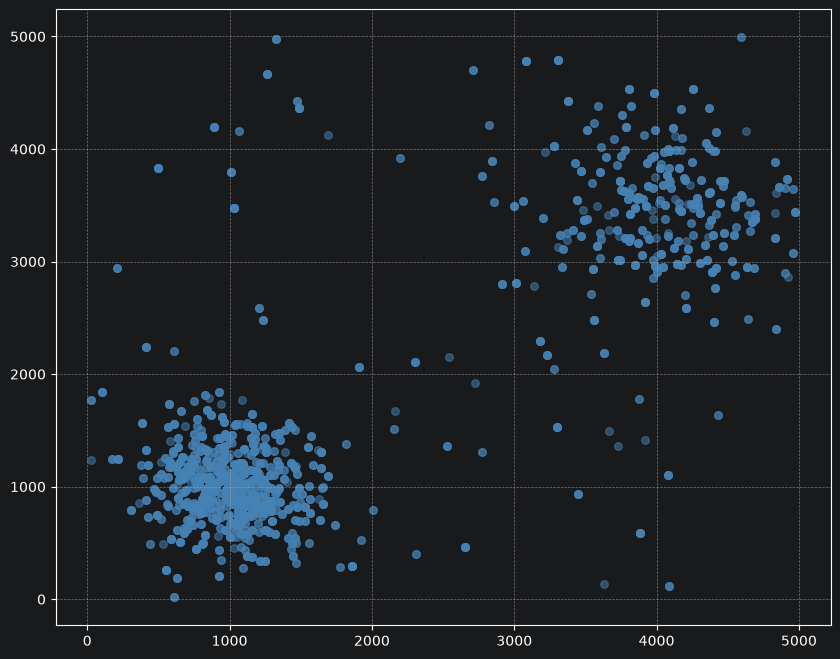

In [16]:
plt.figure(figsize=(10, 8))

plt.scatter(df_train["x"], df_train["y"], alpha=0.5, color="steelblue", s=30)

plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Для объединения с картой осадков необходимо визуально определить кооординаты зон, зона завода, индастриал зон имеет координаты примерно (1000;1000), зона водозабора имеет координаты примерно (4000;3500) классифицировать конкретные  скважины будет легко: вычислять расстояние от скважины до центра этих зон, если оно будет меньше или равно заданому, то скважина относится к этой зоне, если нет проеряем расстояние к другой зоне, если ситуация аналогичная, то просто говорим что это точка в лесу.

In [17]:
def assign_zone(x, y):
    is_industrial = np.hypot(x-1000, y-1000)
    is_intake = np.hypot(x-4000, y-3500)

    if is_industrial <= 900:
        return "Industrial_Zone"
    elif is_intake <= 1200:
        return "Water_Intake_Zone"
    else:
        return "Forest_Zone"

df_train["zone"] = df_train.apply(lambda row: assign_zone(row["x"], row["y"]), axis=1)

In [18]:
df_recharge = pd.read_parquet(f"{base_file_path}recharge.parquet")
df_recharge

,zone,t,recharge_mm
0,Industrial_Zone,2020-01-01,0.65
1,Water_Intake_Zone,2020-01-01,0.00
2,Forest_Zone,2020-01-01,1.89
3,Industrial_Zone,2020-02-01,4.65
4,Water_Intake_Zone,2020-02-01,1.81
...,...,...,...
210,Industrial_Zone,2025-11-01,6.76
212,Forest_Zone,2025-11-01,13.44
213,Industrial_Zone,2025-12-01,6.88
214,Water_Intake_Zone,2025-12-01,5.57


In [19]:
df_recharge.rename(columns={"t":"recharge_t"}, inplace=True)
df_recharge.sort_values(by=["recharge_t"], inplace=True)
df_train.sort_values(by=["t"], inplace=True)

df_train = pd.merge_asof(
    df_train,
    df_recharge[["recharge_t", "zone", "recharge_mm"]],
    left_on="t",
    right_on="recharge_t",
    by="zone",
    direction="backward",
)

df_train.drop(columns=["recharge_t", "zone"], inplace=True)

In [20]:
df_train

,well_id,t,concentration,x,y,z,permeability,lithology,head,pumping_rate,x_center,y_center,total_abstraction_m3_day,recharge_mm
0,Well_0457,2020-01-01,1023.11,967.89,1102.82,-58.96,15.629940,sand,36.306667,0.00,4000.0,3500.0,26714.6,0.65
1,Well_0284,2020-01-03,1.72,628.66,1183.18,-114.51,7.700694,sand,36.170000,0.00,4000.0,3500.0,26714.6,0.65
2,Well_0785,2020-01-03,0.12,495.89,3827.56,-47.48,4.640666,sand,31.453333,0.00,4000.0,3500.0,26714.6,1.89
3,Well_0475,2020-01-05,1.80,1493.49,866.14,-104.15,6.526043,loam,29.921734,0.00,4000.0,3500.0,26714.6,0.65
4,Well_0421,2020-01-05,0.33,1618.22,1322.09,-124.90,11.359716,unknown,32.630000,0.00,4000.0,3500.0,26714.6,0.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,Well_0674,2025-10-27,33.84,3974.96,2854.58,-72.94,4.338842,loam,19.120000,0.00,4000.0,3500.0,29547.1,30.43
2402,Well_0277,2025-10-27,107.69,1059.72,781.86,-78.58,13.788869,sand,36.890000,0.00,4000.0,3500.0,29547.1,24.18
2403,Well_0267,2025-10-29,29.78,1489.72,989.50,-76.60,8.180902,sand,34.420000,0.00,4000.0,3500.0,29547.1,24.18
2404,Well_0141,2025-10-29,79.27,1068.24,899.26,-80.30,15.244325,sand,37.140000,0.00,4000.0,3500.0,29547.1,24.18


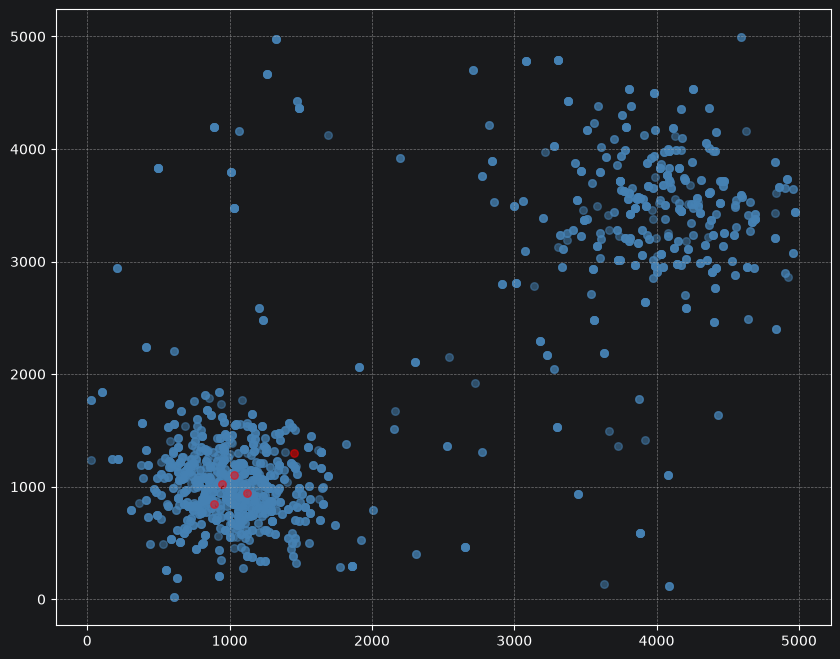

In [21]:
df_source = pd.read_parquet(f"{base_file_path}sources.parquet")

plt.figure(figsize=(10,8))

plt.scatter(x=df_train["x"], y=df_train["y"],  alpha=0.5, color="steelblue", s=30)
plt.scatter(x=df_source["x"], y=df_source["y"], alpha=0.5,  color="red", s=30)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Для объединения с таблицей sources история похожа, необходимо будет циклом перебрать все расстояния, но тут уже так на глаз не скажешь какой радиус у какого источника. Тогда просто создадим 5 новых колонок, и будем мерить расстояние от скважины до каждого источника и выбирать тот, который ближе, при этом расстояние не должно быть слишком большим, условно до 500, ведь дальше нельзя сказать что источник как-то загрязняет скважину. А лучше вовсе не сравнивать расстояние с условной константой и просто сохранить матрицу расстояний до каждого источника, ведь некоторые точки могут загрязняться сразу 2 да и вообще загрязнее пропадает посепенно а не на четкой границе 500.

In [22]:
df_source.set_index("source_id", inplace=True)

for src in ["SRC_01", "SRC_02", "SRC_03", "SRC_04", "SRC_05"]:
    dx = df_train["x"] - df_source.loc[src, "x"]
    dy = df_train["y"] - df_source.loc[src, "y"]
    z_center = (df_source.loc[src, "z_bottom"] + df_source.loc[src, "z_top"]) / 2
    dz = df_train["z"] - z_center

    is_active = (df_train["t"] <= df_source.loc[src, "end_date"]) & (df_train["t"] >= df_source.loc[src, "start_date"])

    df_train[f"{src}_active"] = np.where(is_active, df_source.loc[src, "estimated_release_rate_g_day"], 0)
    df_train[f"{src}_distance"] = np.sqrt(dx ** 2 + dy ** 2 + dz ** 2)

df_source.reset_index(inplace=True)

In [23]:
df_train

,well_id,t,concentration,x,y,z,permeability,lithology,head,pumping_rate,...,SRC_01_active,SRC_01_distance,SRC_02_active,SRC_02_distance,SRC_03_active,SRC_03_distance,SRC_04_active,SRC_04_distance,SRC_05_active,SRC_05_distance
0,Well_0457,2020-01-01,1023.11,967.89,1102.82,-58.96,15.629940,sand,36.306667,0.00,...,450.0,89.542650,0.0,226.978184,0.0,74.729754,0.0,265.415403,0.0,522.811062
1,Well_0284,2020-01-03,1.72,628.66,1183.18,-114.51,7.700694,sand,36.170000,0.00,...,450.0,370.174348,0.0,557.184025,0.0,421.193124,0.0,430.392900,0.0,835.672524
2,Well_0785,2020-01-03,0.12,495.89,3827.56,-47.48,4.640666,sand,31.453333,0.00,...,450.0,2844.101720,0.0,2954.494746,0.0,2779.524392,0.0,3003.545546,0.0,2701.852393
3,Well_0475,2020-01-05,1.80,1493.49,866.14,-104.15,6.526043,loam,29.921734,0.00,...,450.0,569.695096,0.0,389.980849,0.0,526.328512,0.0,607.373775,0.0,445.255996
4,Well_0421,2020-01-05,0.33,1618.22,1322.09,-124.90,11.359716,unknown,32.630000,0.00,...,450.0,739.447325,0.0,636.594633,0.0,637.856956,0.0,872.245434,0.0,202.693726
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,Well_0674,2025-10-27,33.84,3974.96,2854.58,-72.94,4.338842,loam,19.120000,0.00,...,450.0,3538.065944,0.0,3437.532845,180.0,3428.471084,450.0,3679.208498,0.0,2965.740363
2402,Well_0277,2025-10-27,107.69,1059.72,781.86,-78.58,13.788869,sand,36.890000,0.00,...,450.0,266.662998,0.0,180.092294,180.0,325.310781,450.0,187.444670,0.0,651.888115
2403,Well_0267,2025-10-29,29.78,1489.72,989.50,-76.60,8.180902,sand,34.420000,0.00,...,450.0,542.585927,0.0,377.182275,180.0,476.492957,450.0,616.970938,0.0,319.228270
2404,Well_0141,2025-10-29,79.27,1068.24,899.26,-80.30,15.244325,sand,37.140000,0.00,...,450.0,176.320547,0.0,91.294552,180.0,213.781864,450.0,189.810129,0.0,557.430655


In [25]:
df_train.to_parquet(f"{train_file_path}train.parquet")
df_train.to_csv(f"{train_file_path}train.csv")